# 전기 제어회로·와이어 하네스 → 로컬 CAD

**VS Code 커널: `.venv-ml/Scripts/python.exe` (Python 3.11)**

이미지/PDF → 로컬 전처리 → 기호/OCR/선 후보 → 규칙 JSON → 선택적 최소 API → 로컬 의미 JSON → DXF/DWG.
이 노트북은 단계별 흐름을 설명하고 실행합니다. 긴 구현은 같은 폴더의 Python 모듈로 나눠 두었으므로 함수 이름에서 정의로 이동해 볼 수 있습니다.

기본 `Run All`은 합성 구조 JSON 처리와 저장된 실제 Y–Δ 회로 비교 결과 조회를 수행합니다. 회사 도면 전송, 자동 다운로드, 학습, 유료 API, CAD 실행은 하지 않습니다. 해당 단계의 스위치와 경로를 직접 설정해 실행합니다.

**현재 상태:** 로컬 PaddleOCR PP-OCRv5 한글·영문 인식, 중심선·원·곡선 추출과 DXF 비교 화면 구현. EasyOCR는 비교용으로 남겨 두었습니다. 적합한 산업 제어회로 기호 학습과 실제 DWG 연동 검증은 남아 있습니다.

In [1]:
from pathlib import Path
import copy, json, os, subprocess, sys
from IPython.display import display

ROOT = Path.cwd()
assert (ROOT / "pipeline.py").is_file(), "프로젝트 폴더에서 노트북을 실행하세요."
OUTPUT = ROOT / "output"
OUTPUT.mkdir(exist_ok=True)
print("Python:", sys.executable)
subprocess.run([sys.executable, "-X", "utf8", "check_runtime.py"], check=True)

Python: C:\Users\Win11Pro\Documents\ChatGPT\기업프로젝트 cad\.venv-ml\Scripts\python.exe


CompletedProcess(args=['C:\\Users\\Win11Pro\\Documents\\ChatGPT\\기업프로젝트 cad\\.venv-ml\\Scripts\\python.exe', '-X', 'utf8', 'check_runtime.py'], returncode=0)

## 1. 학습 데이터 구성

Y–Δ 회로 예시처럼 접점/접촉기/타이머/전동기/차단기/단자/접지/스플라이스를 구분합니다. 클래스는 회사 도면의 실제 기호와 일치시켜야 합니다.

```
data/my_control_circuits/
  dataset.yaml
  images/train, images/val, images/test
  labels/train, labels/val, labels/test
```

`detect` 라벨 한 줄: `class cx cy width height`.
`obb` 라벨 한 줄: `class x1 y1 x2 y2 x3 y3 x4 y4`.
좌표는 이미지 크기로 나눈 0~1 값입니다. 클래스 번호는 0부터 시작합니다. 동일 원본의 타일·증강본·개정판은 같은 split에 둡니다. 파일 해시 검사는 동일 복사본만 찾으며 유사한 도면의 누수는 직접 관리해야 합니다.

아래 설정은 예시입니다. 없는 파일이나 라벨을 가짜로 생성하지 않습니다. OCR 문자열·핀 연결 정답은 별도로 준비해야 합니다.

In [2]:
from models_local import validate_yolo_dataset, train_yolo, load_yolo, detect_symbols

DATASET = ROOT / "data/my_control_circuits/dataset.yaml"
TASK = "obb"  # 사각 bbox로 라벨링했다면 "detect"
LOCAL_WEIGHTS = ROOT / "models/yolo11n-obb.pt"
RUN_TRAINING = False
example_yaml = {
    "path": str(DATASET.parent), "train": "images/train", "val": "images/val", "test": "images/test",
    "names": ["contactor_coil", "contact_no", "contact_nc", "timer_coil", "motor", "breaker", "terminal", "ground"]
}
print(json.dumps(example_yaml, ensure_ascii=False, indent=2))  # JSON은 YAML의 부분집합
if DATASET.is_file():
    print(validate_yolo_dataset(DATASET, TASK))
else:
    print("학습 데이터 준비 전입니다. 원본 프로젝트별 분할과 라벨을 먼저 준비하세요.")

{
  "path": "C:\\Users\\Win11Pro\\Documents\\ChatGPT\\기업프로젝트 cad\\data\\my_control_circuits",
  "train": "images/train",
  "val": "images/val",
  "test": "images/test",
  "names": [
    "contactor_coil",
    "contact_no",
    "contact_nc",
    "timer_coil",
    "motor",
    "breaker",
    "terminal",
    "ground"
  ]
}
학습 데이터 준비 전입니다. 원본 프로젝트별 분할과 라벨을 먼저 준비하세요.


## 2. 로컬 YOLO 학습

가중치는 이미 로컬에 있는 신뢰할 수 있는 파일만 사용합니다. `None`이면 설치된 YOLO11n 구조로 처음부터 학습하며 사전학습을 받은 모델과 다릅니다. 학습 중 모델 자동 다운로드/외부 로그 전송을 차단합니다.

`epochs=1`은 실행 확인에 불과합니다. mAP는 기호 검출 지표이며, 연결망/문자/치수/CAD 정확도를 나타내지 않습니다.

In [3]:
training = None
if RUN_TRAINING:
    subprocess.run([sys.executable, "-X", "utf8", "check_runtime.py"], check=True)
    import torch
    training = train_yolo(
        DATASET, LOCAL_WEIGHTS, OUTPUT / "training", task=TASK,
        epochs=100, imgsz=1024, device="0" if torch.cuda.is_available() else "cpu", batch=4,
    )
    print(training)
else:
    print("학습 미실행: RUN_TRAINING과 데이터/가중치 경로를 설정하세요.")

학습 미실행: RUN_TRAINING과 데이터/가중치 경로를 설정하세요.


## 3. 이미지/PDF 전처리 — 로컬

이미지 경로를 지정하면 실제 도면을 처리합니다. PDF 페이지는 0부터 시작합니다. 가는 배선을 보존하는 전처리, 로컬 PaddleOCR PP-OCRv5, 중심선 추적과 원·원호 적합을 사용합니다. 맞지 않는 곡선은 폴리라인으로 보존합니다.

In [4]:
from vision import preprocess, extract_geometry, draw_overlay
from pipeline import analyze, classify, finalize, load_rules, suggest_links
from topology import build_topology, compare_revisions

IMAGE_PATH = None  # 예: ROOT / "data/private/control_diagram.pdf"
USE_YOLO = False
USE_OCR = True  # 설치된 로컬 PaddleOCR 모델 사용; 원본 전송 없음
INFERENCE_WEIGHTS = ROOT / "models/control_circuit_best.pt"
OCR_DET_DIR = ROOT / "models/ocr/det"
OCR_REC_DIR = ROOT / "models/ocr/rec"
gray = None

if IMAGE_PATH is None:
    structure = json.loads((ROOT / "sample_structure.json").read_text(encoding="utf-8"))
    print("합성 구조 JSON 실행 예제 — 실도면 인식 결과가 아닙니다.")
else:
    image_path = Path(IMAGE_PATH)
    gray = preprocess(image_path.read_bytes(), image_path.suffix, page_index=0, rotation=0, preserve_thin_lines=True)
    symbols, texts = [], []
    if USE_YOLO:
        detector = load_yolo(INFERENCE_WEIGHTS, task=TASK)
        # 정확한 회사 기호를 BLOCK에 대응하려면 별도 매핑을 지정하세요.
        symbols = detect_symbols(gray, detector, class_map={"ground": {"kind": "ground"}}, conf=0.25)
    if USE_OCR:
        from paddle_ocr_local import read_text
        texts = read_text(gray, min_confidence=.5)
    masked = gray.copy()
    for item in symbols:
        x, y, w, h = item["bbox"]
        masked[max(0,int(y)):min(gray.shape[0],int(y+h+1)), max(0,int(x)):min(gray.shape[1],int(x+w+1))] = 255
    from vectorize_local import extract_vectors
    structure = extract_vectors(masked, texts)
    structure["objects"].extend(symbols)
    structure["texts"] = texts
    structure["graph"] = build_topology(gray, structure["objects"], texts)
    structure = suggest_links(structure)
    display(draw_overlay(gray, structure["objects"], texts))

print("도형:", len(structure["objects"]), "문자:", len(structure["texts"]))

합성 구조 JSON 실행 예제 — 실도면 인식 결과가 아닙니다.
도형: 2 문자: 4


## 4. 단위·의미 규칙

`Φ12`, `24V`, `0.5SQ`는 정규식으로 해석할 수 있습니다. 숫자만 있는 `150`은 길이/핀 번호/수량 후보이며 문맥 확인이 필요합니다. 규칙은 `rules.json`에서 수정합니다. `M1` 같은 기기 표시는 로컬 식별자입니다.

OCR 오인식이 규칙과 우연히 일치할 수도 있으므로 분류와 원본 검토를 구분합니다.

In [5]:
rules = load_rules()
for text in ["Φ12", "24V", "0.5SQ", "150", "M1"]:
    print(text, "→", classify(text, rules))
rows = analyze(structure)
display(rows)

Φ12 → {'roles': ['diameter'], 'value': 12.0, 'unit': 'mm', 'token_kind': 'diameter_mark'}
24V → {'roles': ['voltage'], 'value': 24.0, 'unit': 'V', 'token_kind': 'voltage_unit'}
0.5SQ → {'roles': ['wire_size'], 'value': 0.5, 'unit': 'mm2', 'token_kind': 'area_unit'}
150 → {'roles': ['length', 'pin_number', 'quantity'], 'value': 150.0, 'unit': 'unknown', 'token_kind': 'bare_number'}
M1 → {'roles': ['device_tag'], 'value': 'M1', 'unit': 'none', 'token_kind': 'identifier'}


[{'text_id': 'TEXT_01',
  'raw_text': 'Φ12',
  'roles': ['diameter'],
  'value': 12.0,
  'unit': 'mm',
  'token_kind': 'diameter_mark',
  'candidates': [{'object_id': 'CIRCLE_01',
    'kind': 'circle',
    'evidence': 'leader',
    'roles': ['diameter']}]},
 {'text_id': 'TEXT_02',
  'raw_text': '24V',
  'roles': ['voltage'],
  'value': 24.0,
  'unit': 'V',
  'token_kind': 'voltage_unit',
  'candidates': [{'object_id': 'WIRE_03',
    'kind': 'wire',
    'evidence': 'adjacent',
    'roles': ['voltage']}]},
 {'text_id': 'TEXT_03',
  'raw_text': '0.5SQ',
  'roles': ['wire_size'],
  'value': 0.5,
  'unit': 'mm2',
  'token_kind': 'area_unit',
  'candidates': [{'object_id': 'WIRE_03',
    'kind': 'wire',
    'evidence': 'adjacent',
    'roles': ['wire_size']}]},
 {'text_id': 'TEXT_04',
  'raw_text': '150',
  'roles': ['length', 'pin_number', 'quantity'],
  'value': 150.0,
  'unit': 'unknown',
  'token_kind': 'bare_number',
  'candidates': [{'object_id': 'WIRE_03',
    'kind': 'wire',
    'evi

## 5. 원본 없는 API 호출

전체 JSON을 보내는 방식이 아닙니다. 허용한 범주만 **새 JSON으로 생성**합니다. 실제 수치·OCR 원문·회사 부품번호·좌표·전체 그래프는 포함하지 않습니다. API 응답은 의미와 익명 후보만 포함하며 부족한 문맥은 `unknown`으로 남깁니다.

이 JSON만으로 반환은 가능하지만, 보지 못한 도면이 맞게 추출됐는지 API가 검사할 수는 없습니다. 파생 정보 전송도 불가능한 회사라면 이 기능을 사용하지 않습니다. `store=false`는 무보관 보장이 아닙니다.

In [6]:
from privacy import make_payload, request_selection

RUN_API = False
API_MODEL = os.environ.get("OPENAI_MODEL", "gpt-4.1-mini")
payload, local_alias_map = None, None
for row in rows:
    try:
        payload, local_alias_map = make_payload(row)
        break
    except ValueError:
        continue
print("전송 후보 JSON:")
display(payload)
if RUN_API:
    if payload is None:
        raise ValueError("전송 가능한 범주 후보가 없습니다.")
    from getpass import getpass
    api_key = os.environ.get("OPENAI_API_KEY") or getpass("OpenAI API key: ")
    try:
        api_answer = request_selection(payload, API_MODEL, enabled=True, api_key=api_key)
        print("API 제안:", api_answer)
        print("로컬 객체 후보:", local_alias_map.get(api_answer["target"]))
    finally:
        del api_key
else:
    print("외부 호출 안 함. 실제 연결 확인은 Streamlit의 합성 JSON 테스트도 사용할 수 있습니다.")

전송 후보 JSON:


{'token_kind': 'diameter_mark',
 'unit': 'mm',
 'options': [{'target': 'a',
   'kind': 'circle',
   'evidence': 'leader',
   'roles': ['diameter']}]}

외부 호출 안 함. 실제 연결 확인은 Streamlit의 합성 JSON 테스트도 사용할 수 있습니다.


## 6. 로컬 확인 → 최종 의미 JSON

아래 네 가지 결정은 합성 예제의 정답을 알고 있으므로 명시한 값입니다. 실제 도면에서는 원본을 보며 직접 확인하거나 별도 검증 규칙을 만드세요. API 제안은 자동 적용하지 않습니다.

In [7]:
decisions = {}
if IMAGE_PATH is None:
    decisions = {
        "TEXT_01": {"role": "diameter", "object_id": "CIRCLE_01"},
        "TEXT_02": {"role": "voltage", "object_id": "WIRE_03"},
        "TEXT_03": {"role": "wire_size", "object_id": "WIRE_03"},
        "TEXT_04": {"role": "length", "object_id": "WIRE_03"},
    }
semantic = finalize(structure, decisions)
if "graph" in structure:
    semantic["graph"] = structure["graph"]
(OUTPUT / "semantic.local.json").write_text(json.dumps(semantic, ensure_ascii=False, indent=2), encoding="utf-8")
display(semantic)

{'coordinate_system': 'processed_image_pixels_y_down',
 'objects': [{'object_id': 'CIRCLE_01',
   'shape': 'circle',
   'geometry_px': {'center': [200, 200], 'radius': 60},
   'attributes': {'diameter': {'value': 12.0,
     'unit': 'mm',
     'source_text_id': 'TEXT_01',
     'verification': 'user_confirmed'}}},
  {'object_id': 'WIRE_03',
   'shape': 'wire',
   'geometry_px': {'start': [300, 400], 'end': [1800, 400]},
   'attributes': {'voltage': {'value': 24.0,
     'unit': 'V',
     'source_text_id': 'TEXT_02',
     'verification': 'user_confirmed'},
    'wire_size': {'value': 0.5,
     'unit': 'mm2',
     'source_text_id': 'TEXT_03',
     'verification': 'user_confirmed'},
    'length': {'value': 150.0,
     'unit': 'mm',
     'source_text_id': 'TEXT_04',
     'verification': 'user_confirmed'}}}],
 'unresolved': [],
 'status': 'reviewed'}

## 7. CAD 변환과 저장

좌표는 전처리 후 이미지 기준입니다. `x_mm = x_px * scale`, `y_mm = (height - y_px) * scale`로 바꿉니다. 합성 예제의 0.1 mm/px에서는 원 직경 12 mm, 선 길이 150 mm입니다.

하네스 회로도는 실물 길이대로 그려지지 않을 수 있습니다. OCR 길이 속성을 화면 선 길이와 같다고 가정하지 않습니다. 선/원/원호/스플라인/문자/기호 BLOCK을 Python이 결정하고 속성은 XDATA로 저장합니다. BLOCK은 회사의 로컬 DXF 라이브러리가 있어야 삽입합니다.

In [8]:
from cad import build_dxf, dxf_to_dwg

MM_PER_PIXEL = 0.1  # 합성 예제에만 해당. 실제 도면은 기준 치수로 보정
GEOMETRY_REVIEWED = IMAGE_PATH is None
BLOCK_LIBRARY = None  # 예: ROOT / "models/approved_symbols.dxf"
if GEOMETRY_REVIEWED:
    dxf_bytes = build_dxf(structure, MM_PER_PIXEL, block_library=BLOCK_LIBRARY, semantics=semantic)
    (OUTPUT / "review.dxf").write_bytes(dxf_bytes)
    print("로컬 DXF 저장:", OUTPUT / "review.dxf")
else:
    print("도형·방향·축척을 검토한 뒤 GEOMETRY_REVIEWED=True로 설정하세요.")

RUN_DWG = False
if RUN_DWG:
    assert GEOMETRY_REVIEWED
    dxf_to_dwg(OUTPUT / "review.dxf", OUTPUT / "result.dwg", "AutoCAD.Application")
    # ZWCAD는 "ZWCAD.Application". 기존 DWG 파일을 덮어쓰지 않습니다.

로컬 DXF 저장: C:\Users\Win11Pro\Documents\ChatGPT\기업프로젝트 cad\output\review.dxf


## 8. 개정 전후 의미 비교

픽셀 차이가 아닌 속성값과 객체/연결 변화로 비교합니다. 자동 생성된 ID가 같아도 동일 객체라고 확정하면 안 됩니다. 명시적 대응과 확인 상태를 사용합니다. 아래는 합성 예제의 길이 150→180 변경 시험입니다.

배선 그래프 비교는 `node_matches`, 좌표 변화 비교는 확인된 정합 행렬 `registration`이 추가로 필요합니다. `topology.py`의 `connect_nodes`, `confirm_edges`는 사람이 확인한 연결만 반영합니다. 교차점의 내부 선 분할은 아직 수동 작업이 필요합니다.

In [9]:
if IMAGE_PATH is None:
    revised = copy.deepcopy(semantic)
    wire = next(o for o in revised["objects"] if o["object_id"] == "WIRE_03")
    wire["attributes"]["length"]["value"] = 180
    matches = {o["object_id"]: o["object_id"] for o in semantic["objects"]}
    changes = compare_revisions(semantic, revised, matches, matches_complete=True)
    display(changes)
    (OUTPUT / "changes.demo.json").write_text(json.dumps(changes, ensure_ascii=False, indent=2), encoding="utf-8")

{'changes': [{'kind': 'attribute_changed',
   'before_id': 'WIRE_03',
   'after_id': 'WIRE_03',
   'attribute': 'length',
   'before': {'value': 150.0,
    'unit': 'mm',
    'source_text_id': 'TEXT_04',
    'verification': 'user_confirmed'},
   'after': {'value': 180,
    'unit': 'mm',
    'source_text_id': 'TEXT_04',
    'verification': 'user_confirmed'},
   'status': 'confirmed'}],
 'topology_status': 'unavailable',
 'geometry_status': 'unavailable',
 'notes': ['전후 graph 또는 node_matches가 없어 연결 구조를 비교하지 않았습니다.',
  '검증된 정렬·축척이 없어 기하/경로 길이를 비교하지 않았습니다.']}

## 9. Streamlit과 테스트

PowerShell에서 `.\start_streamlit.ps1` 실행 후 http://127.0.0.1:8501 접속.
화면에서 파일 업로드, API 키 입력/실호출 확인, 의미 대상 확인, JSON/DXF 다운로드, 로컬 CAD의 DWG 저장, 전후 의미 JSON 비교를 수행합니다.

아래 테스트는 합성 데이터만 사용하며 API를 모의 처리합니다. 실도면 성능·API 계정 실연결·DWG 호환성을 대신 검증하지 않습니다.

In [10]:
subprocess.run([sys.executable, "-X", "utf8", "-m", "unittest", "-v", "test_pipeline.py", "test_app.py", "test_vector_preview.py"], check=True)

CompletedProcess(args=['C:\\Users\\Win11Pro\\Documents\\ChatGPT\\기업프로젝트 cad\\.venv-ml\\Scripts\\python.exe', '-X', 'utf8', '-m', 'unittest', '-v', 'test_pipeline.py', 'test_app.py', 'test_vector_preview.py'], returncode=0)

## 10. 첨부 저장소 적용 전후 — 실제 Y–Δ 회로

`drawing-to-dxf`의 중심선 추적·곡선 적합 코드를 검토해 적용했고, Image2CAD의 영상 근거 기반 원 검증 방식을 참고했습니다. OCR은 로컬 PP-OCRv5_server_det + korean_PP-OCRv5_mobile_rec입니다. 첨부 PaddleOCR-VL/Qwen 메타데이터 모델은 실행하지 않았습니다.

아래 셀은 저장된 실제 도면 결과를 표시합니다. `RUN_COMPARISON=True`면 같은 회로를 로컬에서 다시 변환합니다. 학습이나 API 호출은 없습니다. DXF를 다시 읽어 그린 결과를 원본과 비교하므로 단순 원본 이미지 붙여넣기가 아닙니다.

**2픽셀 허용 선 흔적 재현율은 회로 정확도가 아닙니다.** OCR 영역을 제외하며, 문자 오독·기호 분류·전기적 접속·치수 축척의 정답을 평가하지 않습니다. 현재 작은 기기명 오독, 문자 부분의 원 오검출이 남아 있습니다. 0.1 mm/px는 미보정 미리보기 축척입니다.

baseline 선 흔적 재현율: 23.2% 도형: {'line': 55} TEXT: 0
improved 선 흔적 재현율: 98.7% 도형: {'circle': 9, 'line': 128, 'polyline': 113} TEXT: 35
외부 API 호출: 0


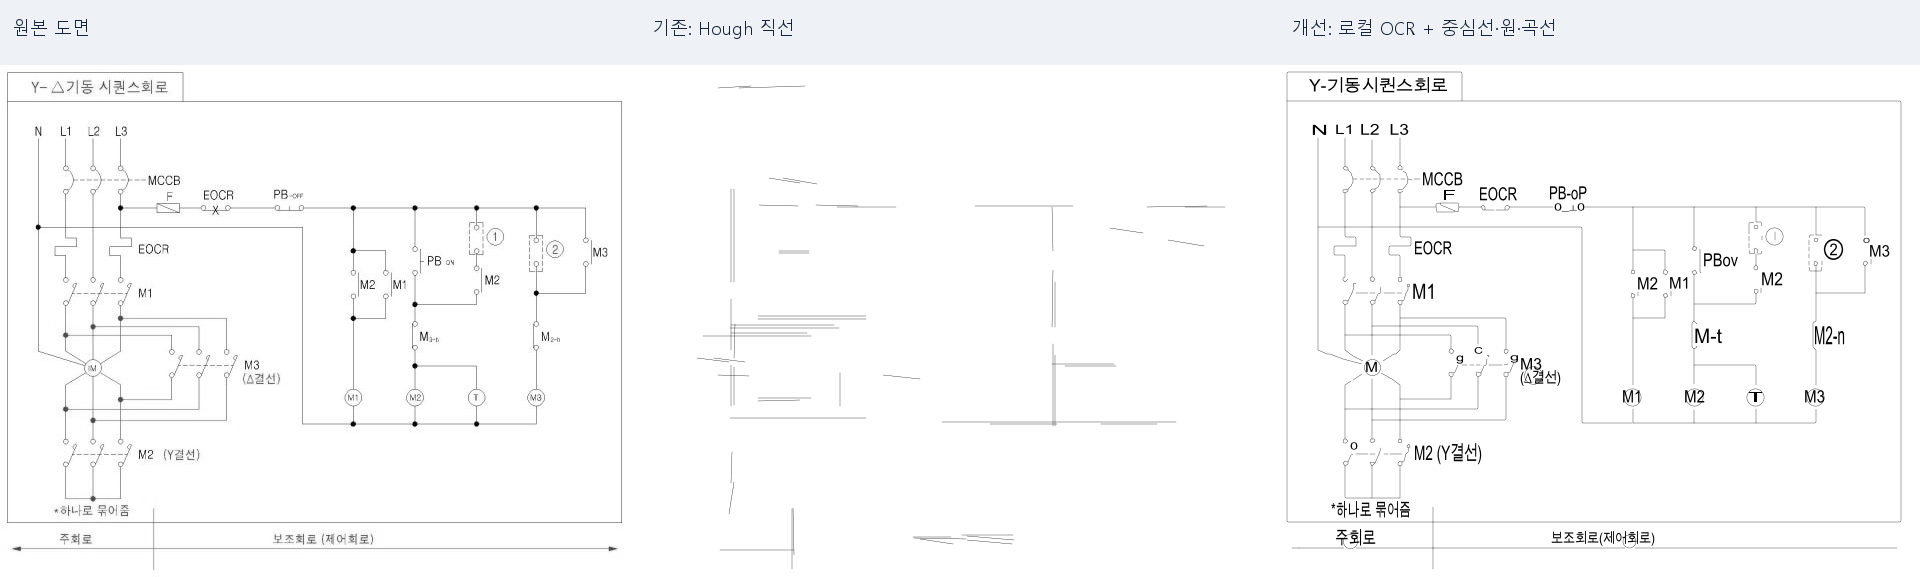

편집 가능한 CAD: C:\Users\Win11Pro\Documents\ChatGPT\기업프로젝트 cad\output\reference_comparison\y_delta_paddle\improved.dxf


In [11]:
from IPython.display import Image

RUN_COMPARISON = False
comparison_dir = OUTPUT / "reference_comparison/y_delta_paddle"
if RUN_COMPARISON:
    from benchmark_preview import compare_file
    compare_file(ROOT / "data/evaluation/user_y_delta.png", comparison_dir, ocr_engine="paddle")
report_path = comparison_dir / "report.json"
if report_path.is_file():
    report = json.loads(report_path.read_text(encoding="utf-8"))
    for method, values in report["methods"].items():
        print(method, "선 흔적 재현율:", f'{values["geometry_ink_recall"]:.1%}',
              "도형:", values["entities"], "TEXT:", values["ocr_texts"])
    print("외부 API 호출:", report["api_calls"])
    display(Image(filename=str(comparison_dir / "comparison.png")))
    print("편집 가능한 CAD:", comparison_dir / "improved.dxf")
else:
    print("RUN_COMPARISON=True로 실제 도면 비교를 실행하세요.")

## 논문을 어떻게 적용하는가

| 연구 | 이 프로젝트에 적용할 부분 | 그대로 해결하지 못하는 부분 |
|---|---|---|
| YOLOv11-OBB + Donut 제조도면 파싱 | 회전 주석 검출·패치의 구조 JSON | 전기 배선 그래프·DWG 복원 |
| Deep Vectorization of Technical Drawings | 래스터 선·곡선 벡터화 후보 | 기호 의미·배선 접속·CAD 객체 분류 |
| PID2Graph / P&ID 그래프 연구 | 검출과 연결 평가 구조 | 하네스 도메인 전이·핀 정답·CAD 저장 |

정확한 논문/공식 저장소와 한계는 `research_detection.md`, `research_vectorization.md`, `research_connectivity.md`에 정리했습니다. 데이터 선정 수정 내역은 `research_datasets.md`에 있습니다.

다음 실제 학습에는 적합한 산업 제어회로의 라벨과 독립 검증 도면이 필요합니다. 기호 학습이 성공해도 OCR, 접속 복원, 도면 정합, BLOCK 템플릿은 별도 검증해야 합니다.